# Pengumpulan Data & Uji Kestasioneran
**Objek Data:** Penolakan Calon Pendonor Darah Akibat Kriteria Hemoglobin (HB)  
**Sumber Data:** File `data_tolak_hb.csv` (243 Hari Observasi Operasional UDD PMI Kota Surabaya)  
**Tujuan:** Membuktikan bahwa data deret berkala yang dikumpulkan bersifat **Non-Stasioner** melalui observasi visual dan uji statistik formal.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

### Memuat file CSV hasil pembacaan agregasi

In [15]:
df = pd.read_csv('data_tolak_hb.csv')
df['TglPeriksa'] = pd.to_datetime(df['TglPeriksa'])
df.set_index('TglPeriksa', inplace=True)
df = df.asfreq('D')

print(f"Total Baris Data (Hari): {len(df)}")
display(df.head())

Total Baris Data (Hari): 243


,Jumlah_Pendonor
TglPeriksa,
2026-01-01,77
2026-01-02,52
2026-01-03,31
2026-01-04,33
2026-01-05,30


### Kalkulasi Rolling Statistics (Jendela 30 Hari)

In [16]:
window_size = 30
df['Rolling_Mean'] = df['Jumlah_Pendonor'].rolling(window=window_size).mean()
df['Rolling_Std'] = df['Jumlah_Pendonor'].rolling(window=window_size).std()

### Plot Visualisasi Pembuktian Non-Stasioner

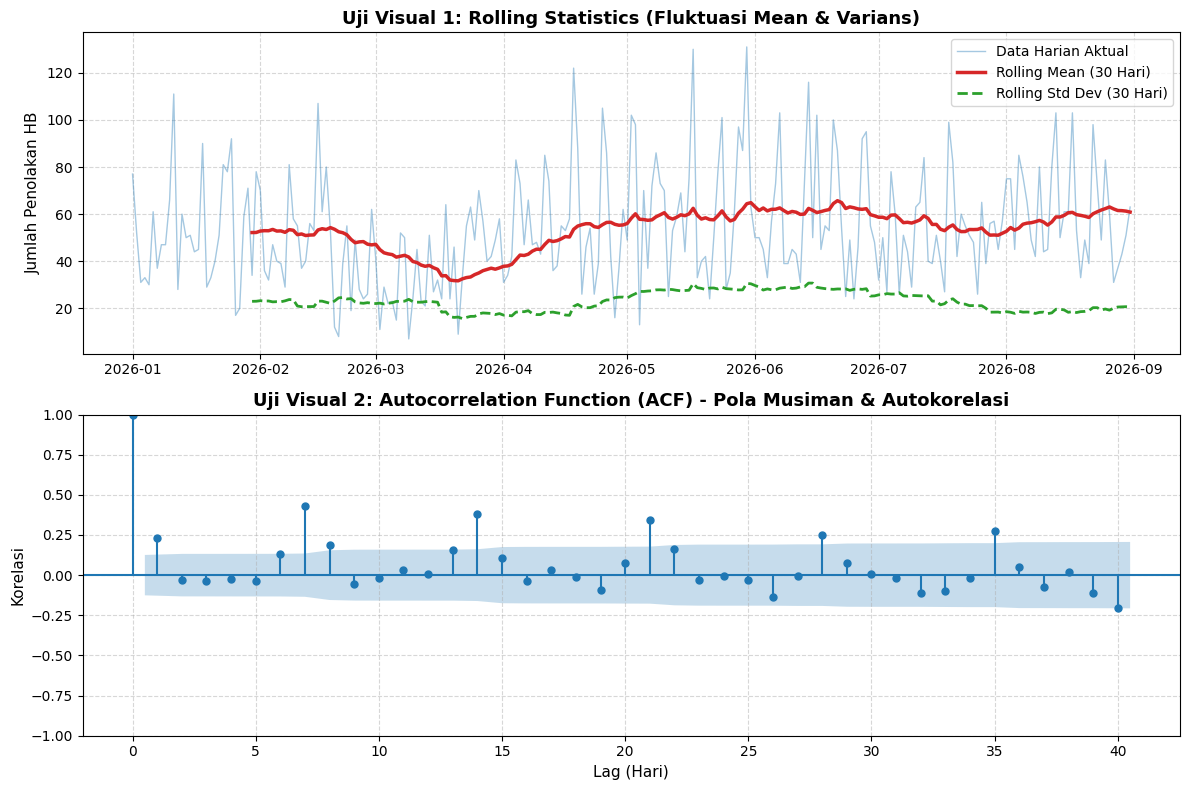

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Subplot 1: Data Harian vs Rolling Mean & Standard Deviation
axes[0].plot(df.index, df['Jumlah_Pendonor'], label='Data Harian Aktual', color='#1f77b4', alpha=0.4, linewidth=1)
axes[0].plot(df.index, df['Rolling_Mean'], label='Rolling Mean (30 Hari)', color='#d62728', linewidth=2.5)
axes[0].plot(df.index, df['Rolling_Std'], label='Rolling Std Dev (30 Hari)', color='#2ca02c', linewidth=2, linestyle='--')
axes[0].set_title('Uji Visual 1: Rolling Statistics (Fluktuasi Mean & Varians)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Jumlah Penolakan HB', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Autocorrelation Function (ACF) Plot
plot_acf(df['Jumlah_Pendonor'].dropna(), ax=axes[1], lags=40, color='#1f77b4')
axes[1].set_title('Uji Visual 2: Autocorrelation Function (ACF) - Pola Musiman & Autokorelasi', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Lag (Hari)', fontsize=11)
axes[1].set_ylabel('Korelasi', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Uji Formal Uji Augmented Dickey-Fuller (ADF Test)

In [18]:
adf_result = adfuller(df['Jumlah_Pendonor'].dropna())

print("=" * 55)
print("HASIL UJI STATISTIK AUGMENTED DICKEY-FULLER (ADF TEST)")
print("=" * 55)
print(f"ADF Statistic      : {adf_result[0]:.4f}")
print(f"p-value            : {adf_result[1]:.4f}")
print(f"Lags Used          : {adf_result[2]}")
print(f"Number of Obs      : {adf_result[3]}")
print(f"Critical Value 1%  : {adf_result[4]['1%']:.4f}")
print(f"Critical Value 5%  : {adf_result[4]['5%']:.4f}")
print(f"Critical Value 10% : {adf_result[4]['10%']:.4f}")
print("=" * 55)

if adf_result[1] > 0.05:
    print("Kesimpulan: p-value > 0.05 (Gagal Tolak H0) -> Data NON-STASIONER.")
    print("Tindakan  : Perlu proses diferensiasi (differencing / df.diff()).")
else:
    print("Kesimpulan: p-value <= 0.05 (Tolak H0) -> Data STASIONER.")
    print("Tindakan  : Data siap digunakan langsung untuk pemodelan.")

HASIL UJI STATISTIK AUGMENTED DICKEY-FULLER (ADF TEST)
ADF Statistic      : -1.8998
p-value            : 0.3322
Lags Used          : 13
Number of Obs      : 229
Critical Value 1%  : -3.4592
Critical Value 5%  : -2.8742
Critical Value 10% : -2.5735
Kesimpulan: p-value > 0.05 (Gagal Tolak H0) -> Data NON-STASIONER.
Tindakan  : Perlu proses diferensiasi (differencing / df.diff()).


### Pembahasan Hasil Uji Kestasioneran Data (Untuk Laporan Progres)

Berdasarkan analisis deret berkala pada data `data_tolak_hb.csv` (243 hari observasi), diperoleh bukti kuantitatif dan kualitatif bahwa data bersifat **NON-STASIONER**:

1. **Uji Visual 1 (Rolling Statistics):** Garis *Rolling Mean* (merah) tidak mendatar secara konstan, melainkan menunjukkan pergeseran tren yang bernilai tidak stabil seiring berjalannya waktu (menurun pada Maret, lalu melonjak naik di Mei–Juni).
2. **Uji Visual 2 (Autocorrelation Function / ACF):** Plot ACF menunjukkan lonjakan korelasi berulang yang melampaui rentang signifikansi biru pada kelipatan lag ke-7, 14, 21, dan 28. Hal ini mengindikasikan adanya **pola musiman mingguan (weekly seasonality)**.
3. **Uji Hipotesis ADF Test:** Nilai *p-value* sebesar **0.3322** ($> 0.05$) dan nilai statistik ADF ($-1.8998 > -2.8742$). Hal ini mengonfirmasi secara statistik formal bahwa hipotesis nol ($H_0$) gagal ditolak, sehingga data terbukti sah **Non-Stasioner**.

---


### Metodologi & Alasan Pemilihan Model (SARIMA vs. Meta Prophet)

Pemodelan peramalan pada proyek ini membandingkan dua pendekatan time series yang berbeda karakter dalam menangani data **non-stasioner**:

#### 1. Model Utama: SARIMA (Seasonal Autoregressive Integrated Moving Average)
* **Kategori:** Model Statistik Klasik Parametrik.
* **Alasan Pemilihan:** SARIMA merupakan standar emas (*gold standard*) dalam analisis runtun waktu klasik untuk data yang memiliki tren non-stasioner dan pola musiman (*seasonality*).
* **Penerapan pada Data:** Berdasarkan plot ACF, terdapat lonjakan autokorelasi pada lag kelipatan 7 (musiman mingguan, $s=7$). SARIMA membutuhkan penanganan non-stasioneritas secara eksplisit melalui proses pembedaan (*differencing* $d=1$) sebelum menentukan orde $(p,d,q)(P,D,Q)_7$.

#### 2. Model Pembanding: Meta Prophet (Facebook Prophet)
* **Kategori:** Model Additive Time Series berbasis Machine Learning.
* **Alasan Pemilihan:** Prophet dirancang khusus oleh Meta untuk menangani data runtun waktu harian yang kompleks, memiliki pola musiman berulang, dan perubahan tren mendadak (*changepoints*).
* **Penerapan pada Data:** Berbeda dengan SARIMA, Prophet tidak mengharuskan data distasionerkan secara manual terlebih dahulu. Prophet secara otomatis mengurai data menjadi komponen tren non-linear, musiman mingguan/tahunan, dan efek hari libur.

#### 3. Tujuan Komparasi
Studi komparasi ini bertujuan untuk menguji apakah **transformasi statistik manual dengan diferensiasi (SARIMA)** memberikan akurasi (RMSE, MAE, MAPE) yang lebih baik daripada **pendekatan dekomposisi otomatis (Prophet)** dalam memprediksi fluktuasi penolakan donor HB di UDD PMI Kota Surabaya.